In [29]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [30]:
adata=sc.read_h5ad('/home/julia/final_clustering.h5ad')

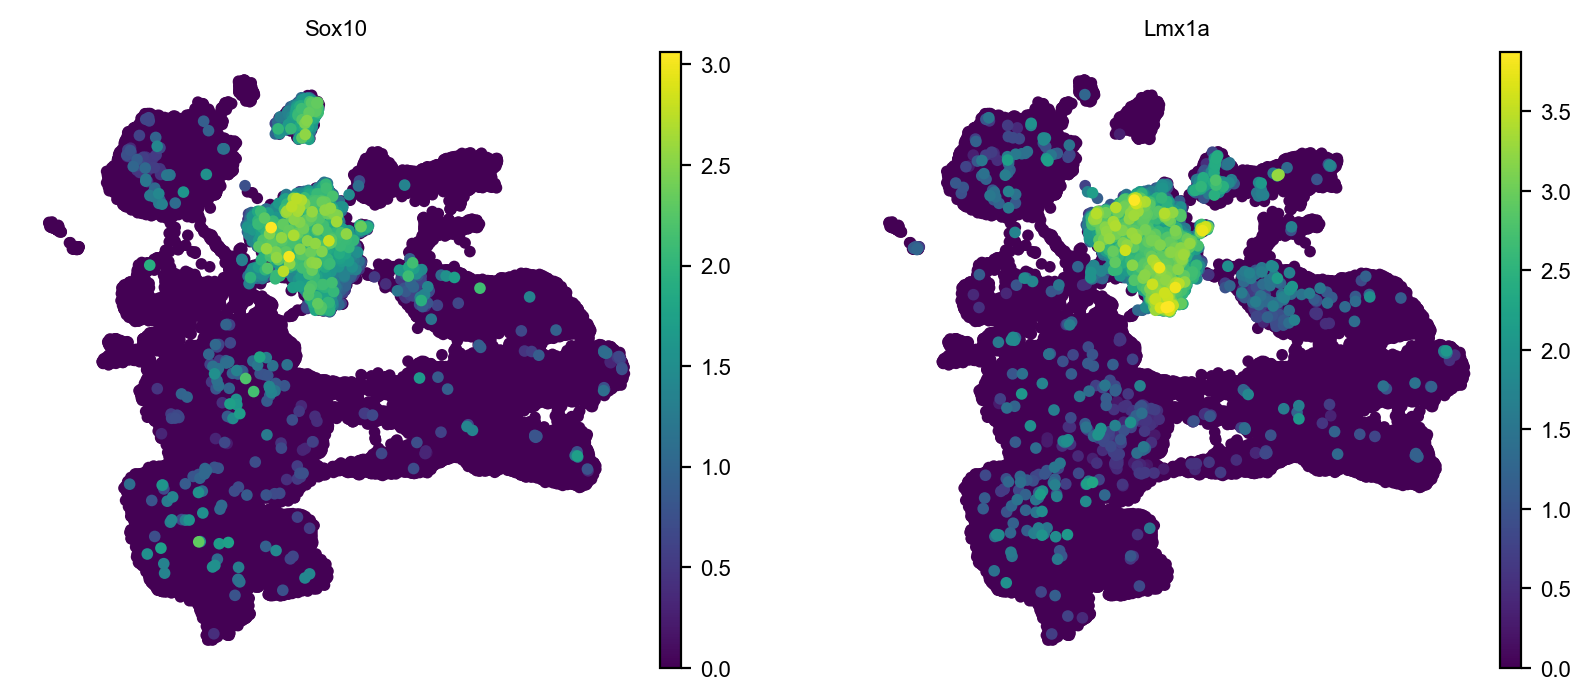

In [31]:
sc.pl.umap(adata, color=['Sox10','Lmx1a'], frameon=False, size=70, legend_loc='on data')

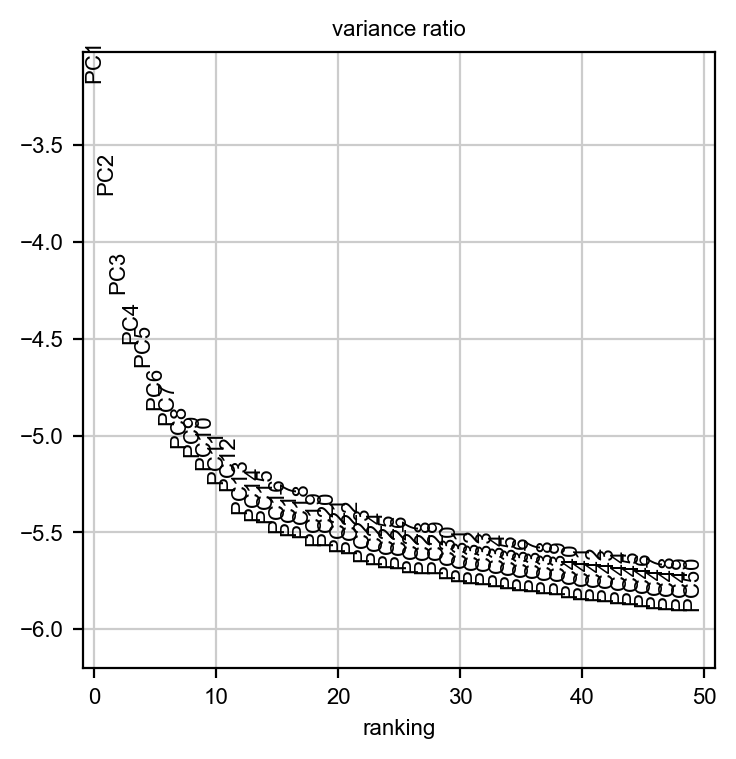

In [32]:
KEEP = ["24,0", "24,1"]
KEY = "leiden_sub"

sub2 = adata[adata.obs[KEY].isin(KEEP)].copy()

sc.pp.highly_variable_genes(
    sub2,
    flavor="seurat_v3",
    layer="counts",
    n_top_genes=3000
)

tmp = sub2[:, sub2.var["highly_variable"]].copy()

sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=50)
sc.pl.pca_variance_ratio(tmp, n_pcs=50, log=True)

sub2.obsm["X_pca"] = tmp.obsm["X_pca"].copy()
sub2.uns["pca"] = tmp.uns["pca"].copy()

del tmp

In [33]:
sc.tl.pca(sub2, n_comps=100)

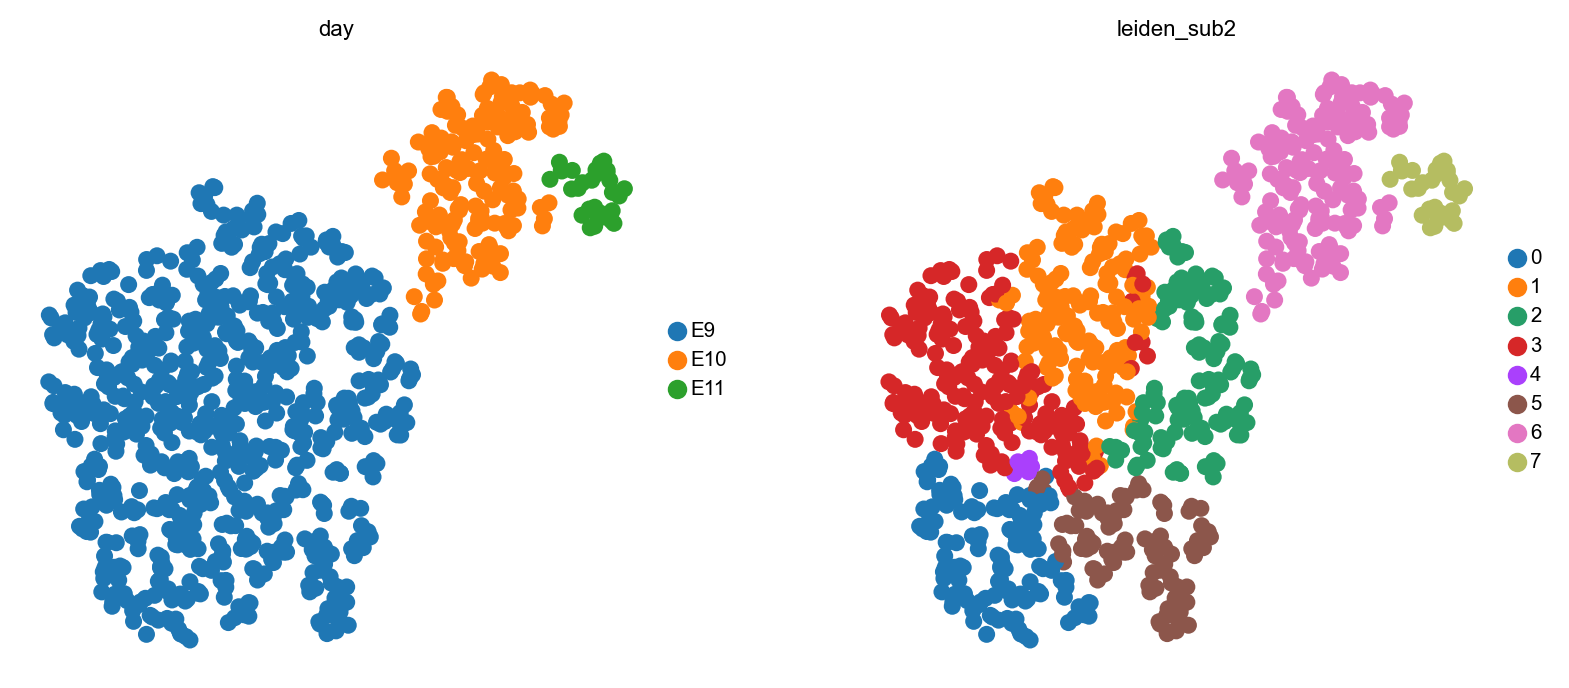

In [34]:
sc.pp.neighbors(
    sub2,
    n_neighbors=30,
    n_pcs=50,
    use_rep="X_pca"
)

sc.tl.umap(
    sub2,
    min_dist=0.8,
    spread=1.0,
    random_state=42
)

sc.tl.leiden(
    sub2,
    resolution=0.5,
    key_added="leiden_sub2",
    flavor="igraph",
    n_iterations=2,
    directed=False
)

sc.pl.umap(
    sub2,
    color=[
        "day","leiden_sub2" ],
    frameon=False,
    size=150,
    ncols=3
)


In [35]:
sub2.write_h5ad('lens_sub_umap.h5ad')

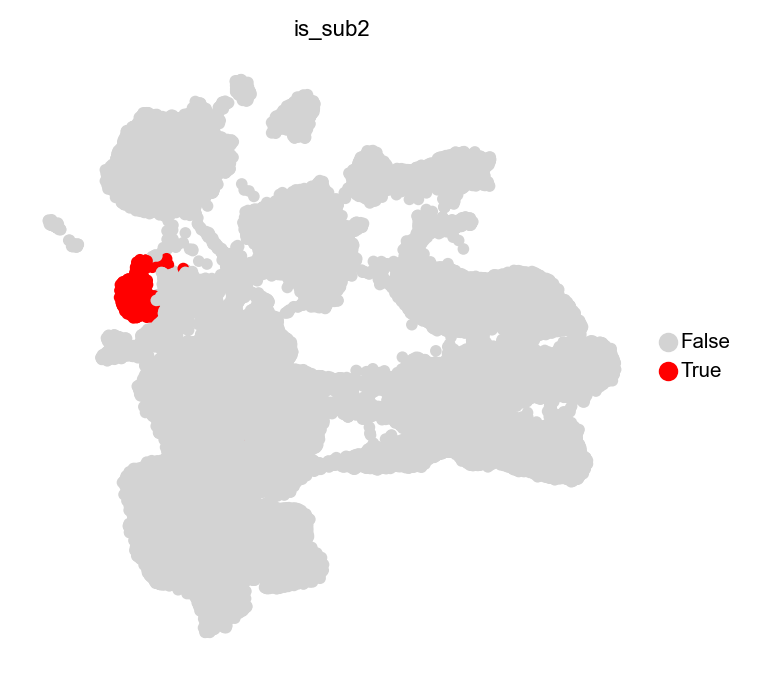

In [36]:
import scanpy as sc
import numpy as np

# Mark all cells belonging to sub2
adata.obs['is_sub2'] = adata.obs_names.isin(sub2.obs_names).astype(str)

# Plot on original adata UMAP
sc.pl.umap(
    adata,
    color='is_sub2',
    palette={'False': 'lightgrey', 'True': 'red'},
    size=70,
    frameon=False,
    sort_order=False,
 #save='lens_all_sub2_on_adata.pdf'
)

In [37]:
GROUPBY = "leiden_sub"

CLUSTERS = ["24,0", "24,1"]

sc.tl.rank_genes_groups(
    adata,
    groupby=GROUPBY,
    groups=CLUSTERS,
    reference="rest",
    method="wilcoxon",
    use_raw=False,
    pts=True,
    key_added="markers_24"
)

Number of genes to plot: 15

Saved files:
/home/julia/UMAP_markers_final.pdf
/home/julia/UMAP_markers_final.svg


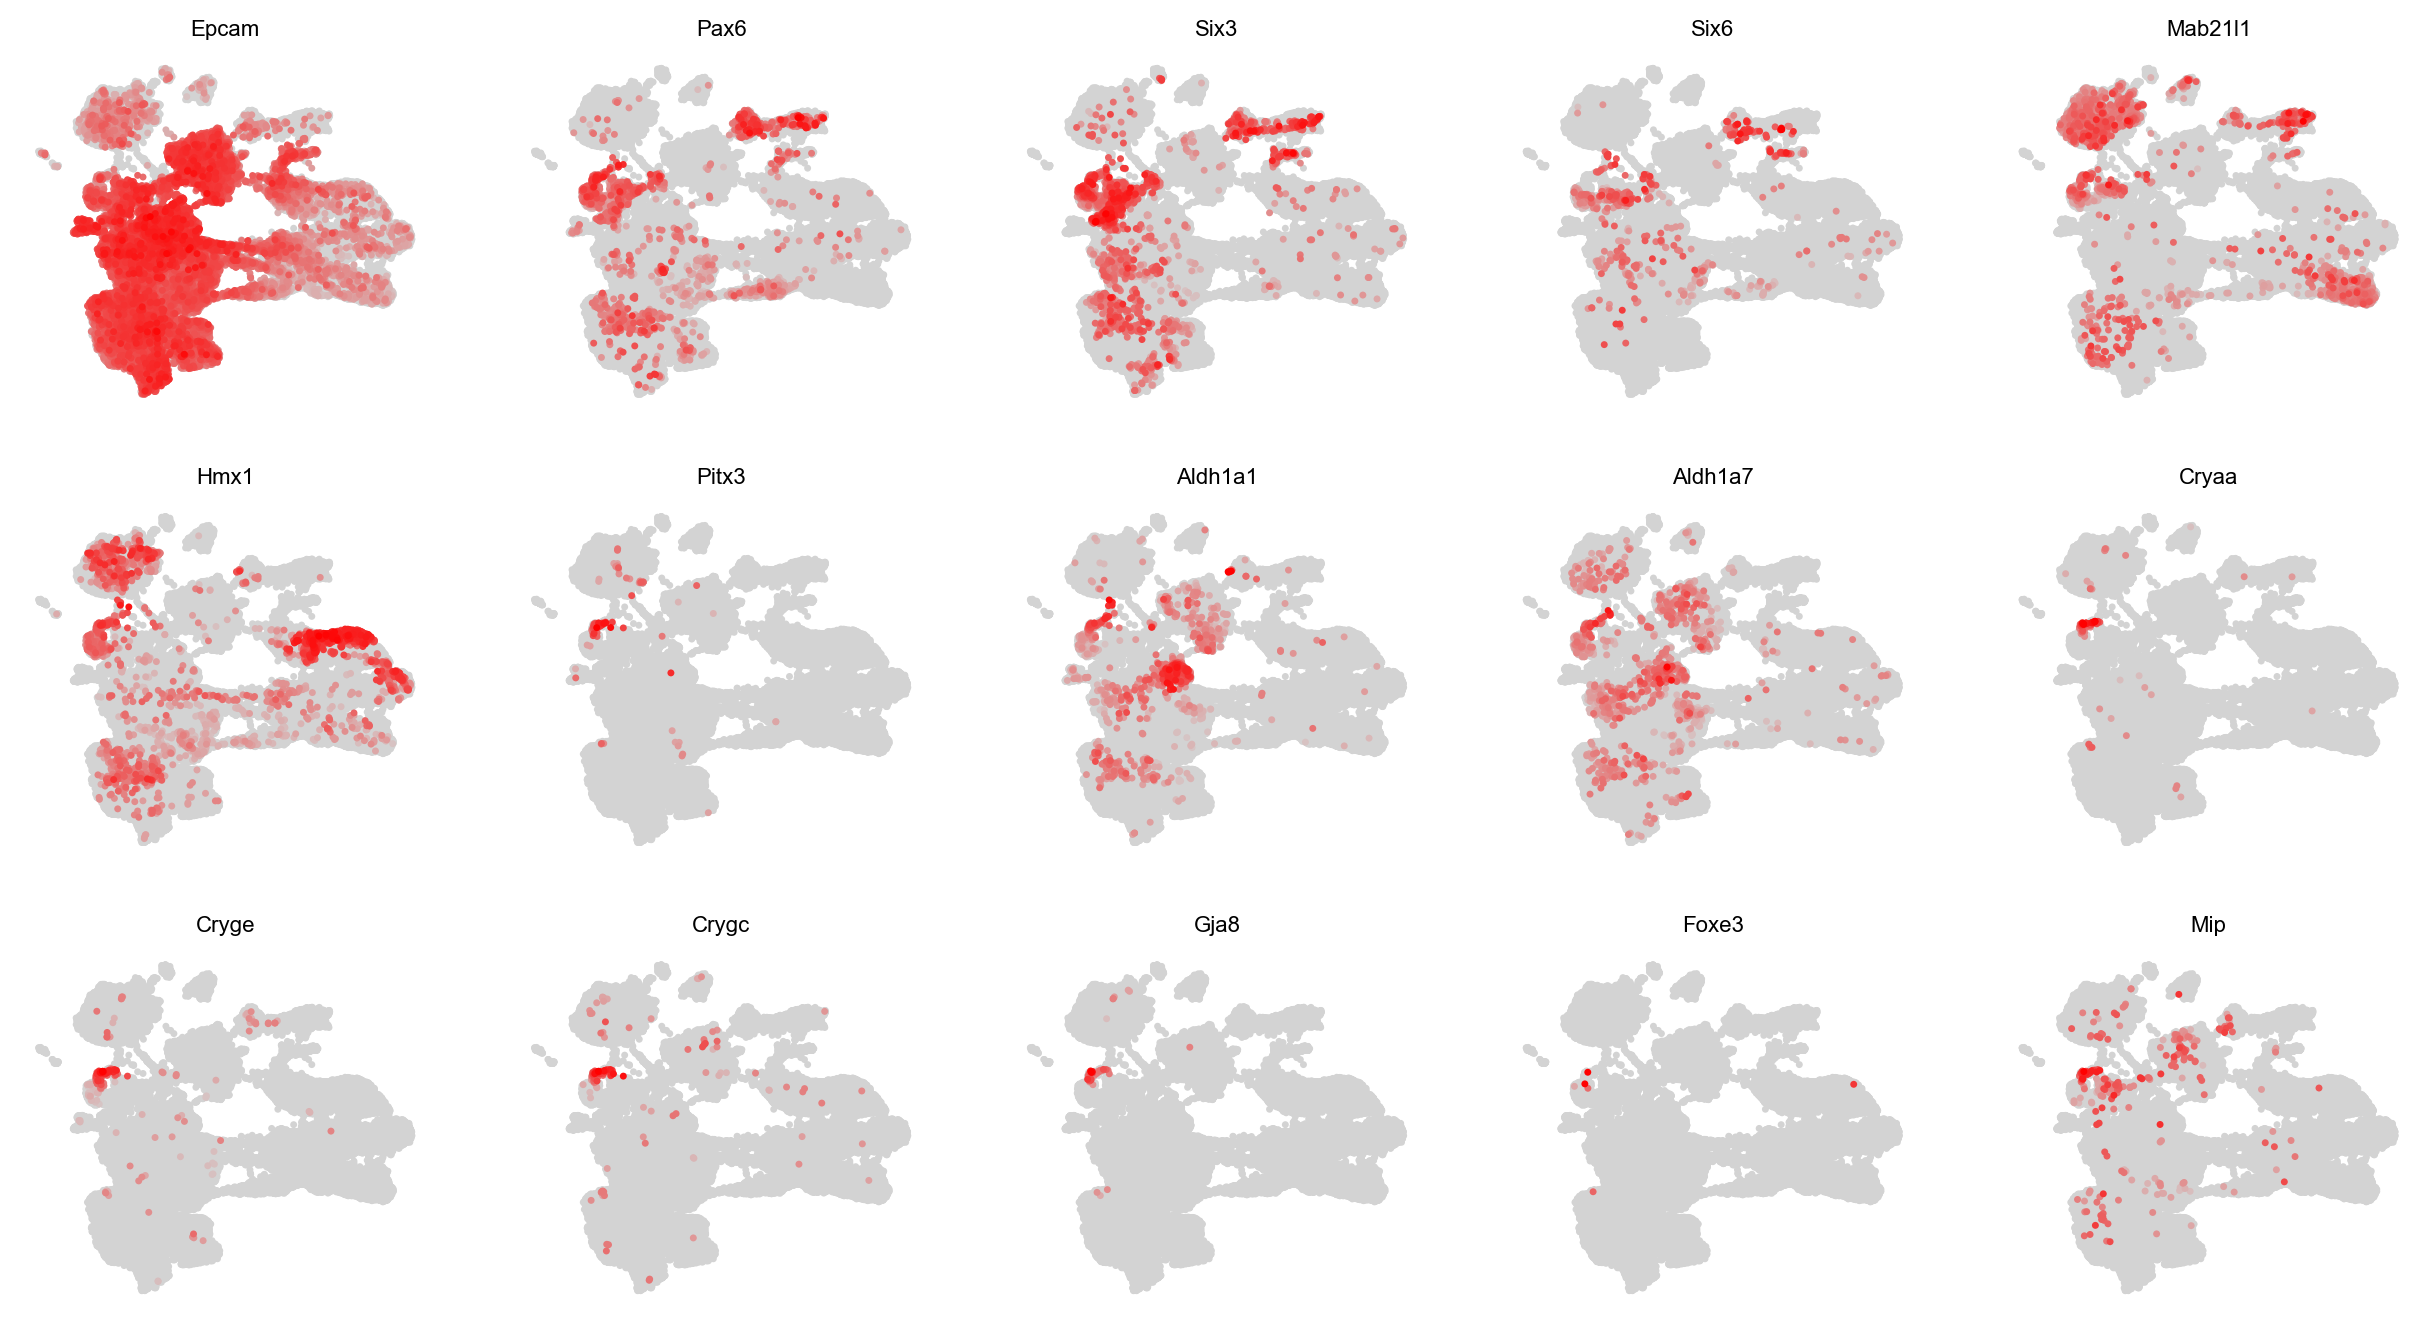

In [38]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
import math

# ============================================================
# 1. FIGURE SETTINGS — ADJUST HERE
# ============================================================

TITLE_SIZE = 8        # Gene names above each UMAP
COLORBAR_SIZE = 8     # Colorbar numbers
NCOLS = 5            # Number of UMAPs per row
POINT_SIZE = 25        # Size of individual cells
DPI = 300              # Resolution for rasterized UMAP points

PANEL_WIDTH = 3.0      # Width per UMAP (inches)
PANEL_HEIGHT = 2.5     # Height per UMAP (inches)

# Output directory
OUTDIR = Path.home()
FILENAME = "UMAP_markers_final"

# Custom colormap
grey_red = LinearSegmentedColormap.from_list(
    "grey_red",
    ["lightgrey", "red"]
)

# Arial font and editable text in Illustrator
mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": TITLE_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "figure.dpi": 100,
    "savefig.dpi": DPI,
})

sc.set_figure_params(
    vector_friendly=True,
    dpi=100,
    dpi_save=DPI,
    fontsize=TITLE_SIZE
)

# ============================================================
# 2. MARKER GENES ORDERED BY CELL TYPE
# ============================================================

genes = [
    # Lens placode / early development
   'Epcam', "Pax6",
    "Six3","Six6",
    "Mab21l1",
    "Hmx1",


    # Lens development / differentiation
    "Pitx3",
   
    "Aldh1a1", "Aldh1a7",'Hmx1',

    # Lens fiber differentiation
    "Cryaa",
  #  "Crybb3",
  #   "Cryab",
    "Cryge",
    "Crygc",
    "Gja8",'Foxe3',"Cryaa",  "Cryge", "Crygc",'Mip'
]



# ============================================================
# 3. CHECK GENE AVAILABILITY
# ============================================================

# Remove duplicates, preserve order
genes = list(dict.fromkeys(genes))

# Include only genes available in AnnData
missing_genes = [
    g for g in genes
    if g not in adata.var_names
]

genes = [
    g for g in genes
    if g in adata.var_names
]

print(f"Number of genes to plot: {len(genes)}")

if missing_genes:
    print("\nMissing genes:")
    print(missing_genes)

if not genes:
    raise ValueError("No selected genes found in adata.var_names")

# ============================================================
# 4. GENERATE UMAP
# ============================================================

NROWS = math.ceil(len(genes) / NCOLS)

fig_width = NCOLS * PANEL_WIDTH
fig_height = NROWS * PANEL_HEIGHT

fig = sc.pl.umap(
    adata,
    color=genes,
    ncols=NCOLS,
    cmap=grey_red,
    size=POINT_SIZE,
    frameon=False,
    show=False,colorbar_loc=None,
    return_fig=True
)

# Set complete figure dimensions
fig.set_size_inches(fig_width, fig_height)

# ============================================================
# 5. RASTERIZE ONLY UMAP POINTS
# ============================================================

# Colorbars, gene names, and other text remain vectors
for ax in fig.axes:

    if ax.get_label() == "<colorbar>":
        continue

    for collection in ax.collections:
        collection.set_rasterized(True)

# ============================================================
# 6. ADJUST FONT SIZES
# ============================================================

for ax in fig.axes:

    # Gene titles
    if ax.get_title() in genes:
        ax.title.set_fontsize(TITLE_SIZE)
        ax.title.set_fontfamily("Arial")
        ax.title.set_fontweight("normal")

    # Colorbar labels
    else:
        ax.tick_params(
            axis="both",
            labelsize=COLORBAR_SIZE
        )

        for label in ax.get_yticklabels():
            label.set_fontfamily("Arial")

# ============================================================
# 7. SAVE PDF AND SVG IN WORKING DIRECTORY
# ============================================================

pdf_path = OUTDIR / f"{FILENAME}.pdf"
svg_path = OUTDIR / f"{FILENAME}.svg"

fig.savefig(
    pdf_path,
    format="pdf",
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white"
)

fig.savefig(
    svg_path,
    format="svg",
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white"
)

print("\nSaved files:")
print(pdf_path)
print(svg_path)

# ============================================================
# 8. DISPLAY
# ============================================================

plt.show()



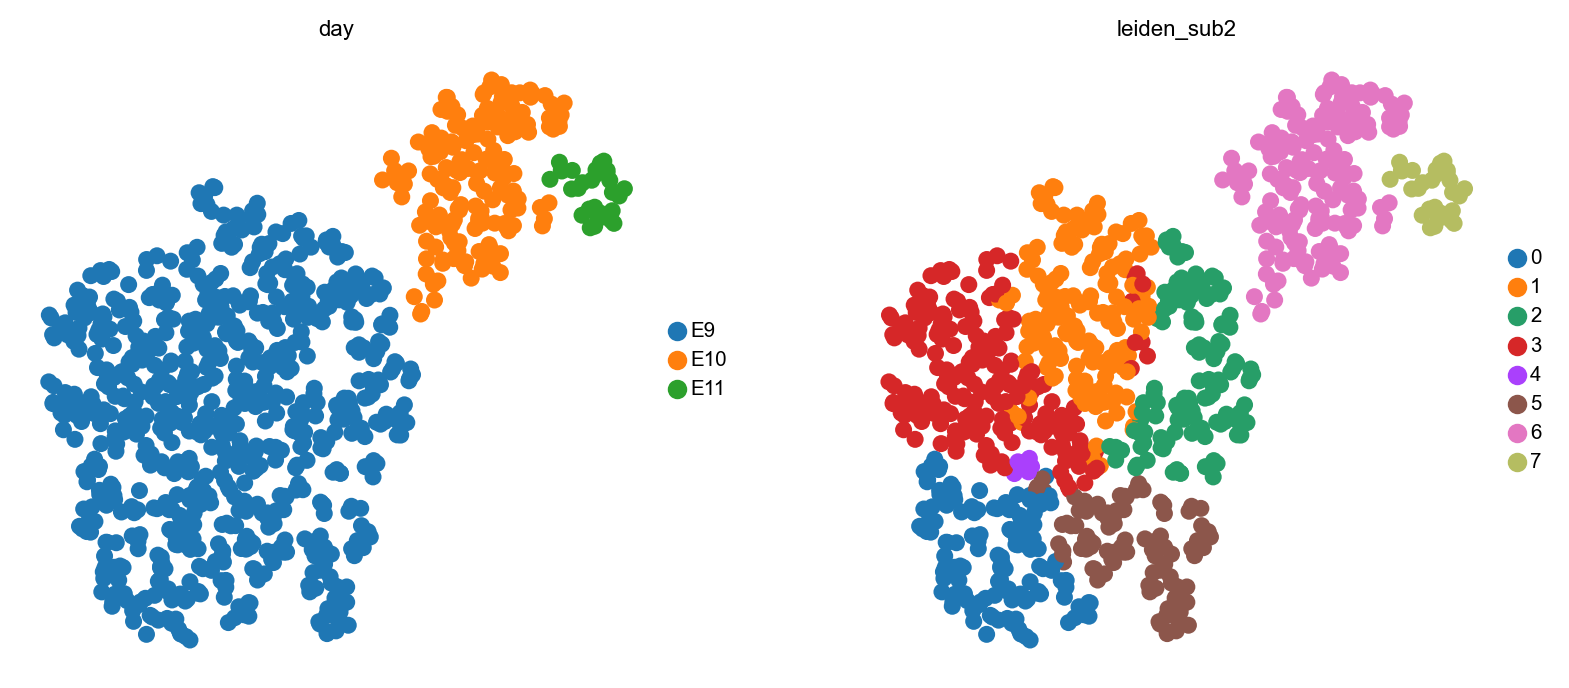

In [39]:
sc.pl.umap( sub2,color=[ "day","leiden_sub2" ],  frameon=False,
    size=150,
    ncols=3
)


/home/julia/miniconda3/envs/Scanpy/lib/python3.12/site-packages/scanpy/plotting/_utils.py:471: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


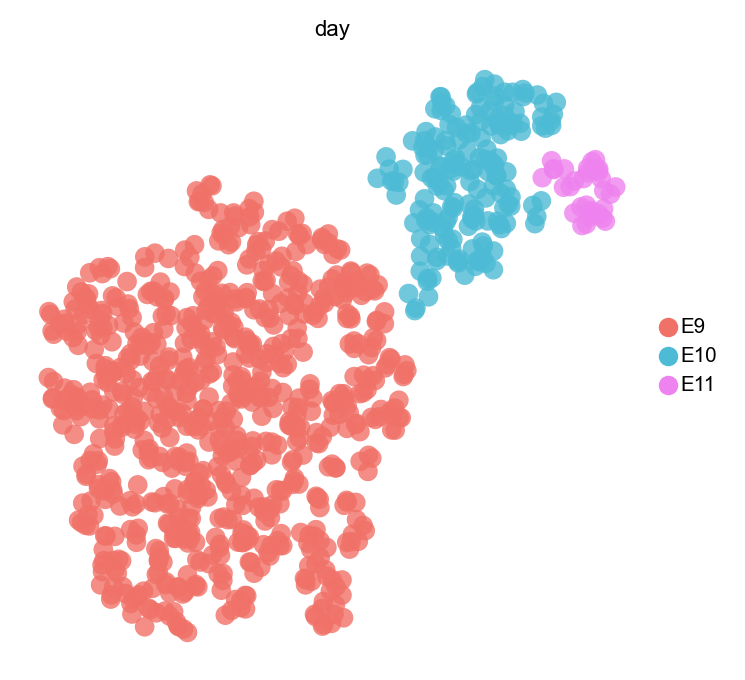

In [40]:
import numpy as np

# shuffle cell order so neither day sits on top
np.random.seed(0)
idx = np.random.permutation(sub2.n_obs)

sc.pl.umap(
    sub2[idx],
    color="day",
    palette={"E9": "#F07167","E11": "violet", "E10": "#4DBBD5"},
    size=200,
    frameon=False,
    legend_loc="right margin", alpha=0.8,
# save="_day_Lens.pdf",
)

In [41]:
sub2.write_h5ad('lens_subset.h5ad')

In [42]:
adata=sub2.copy()

Number of genes to plot: 21
/home/julia/UMAP_markers_final.pdf
/home/julia/UMAP_markers_final.svg


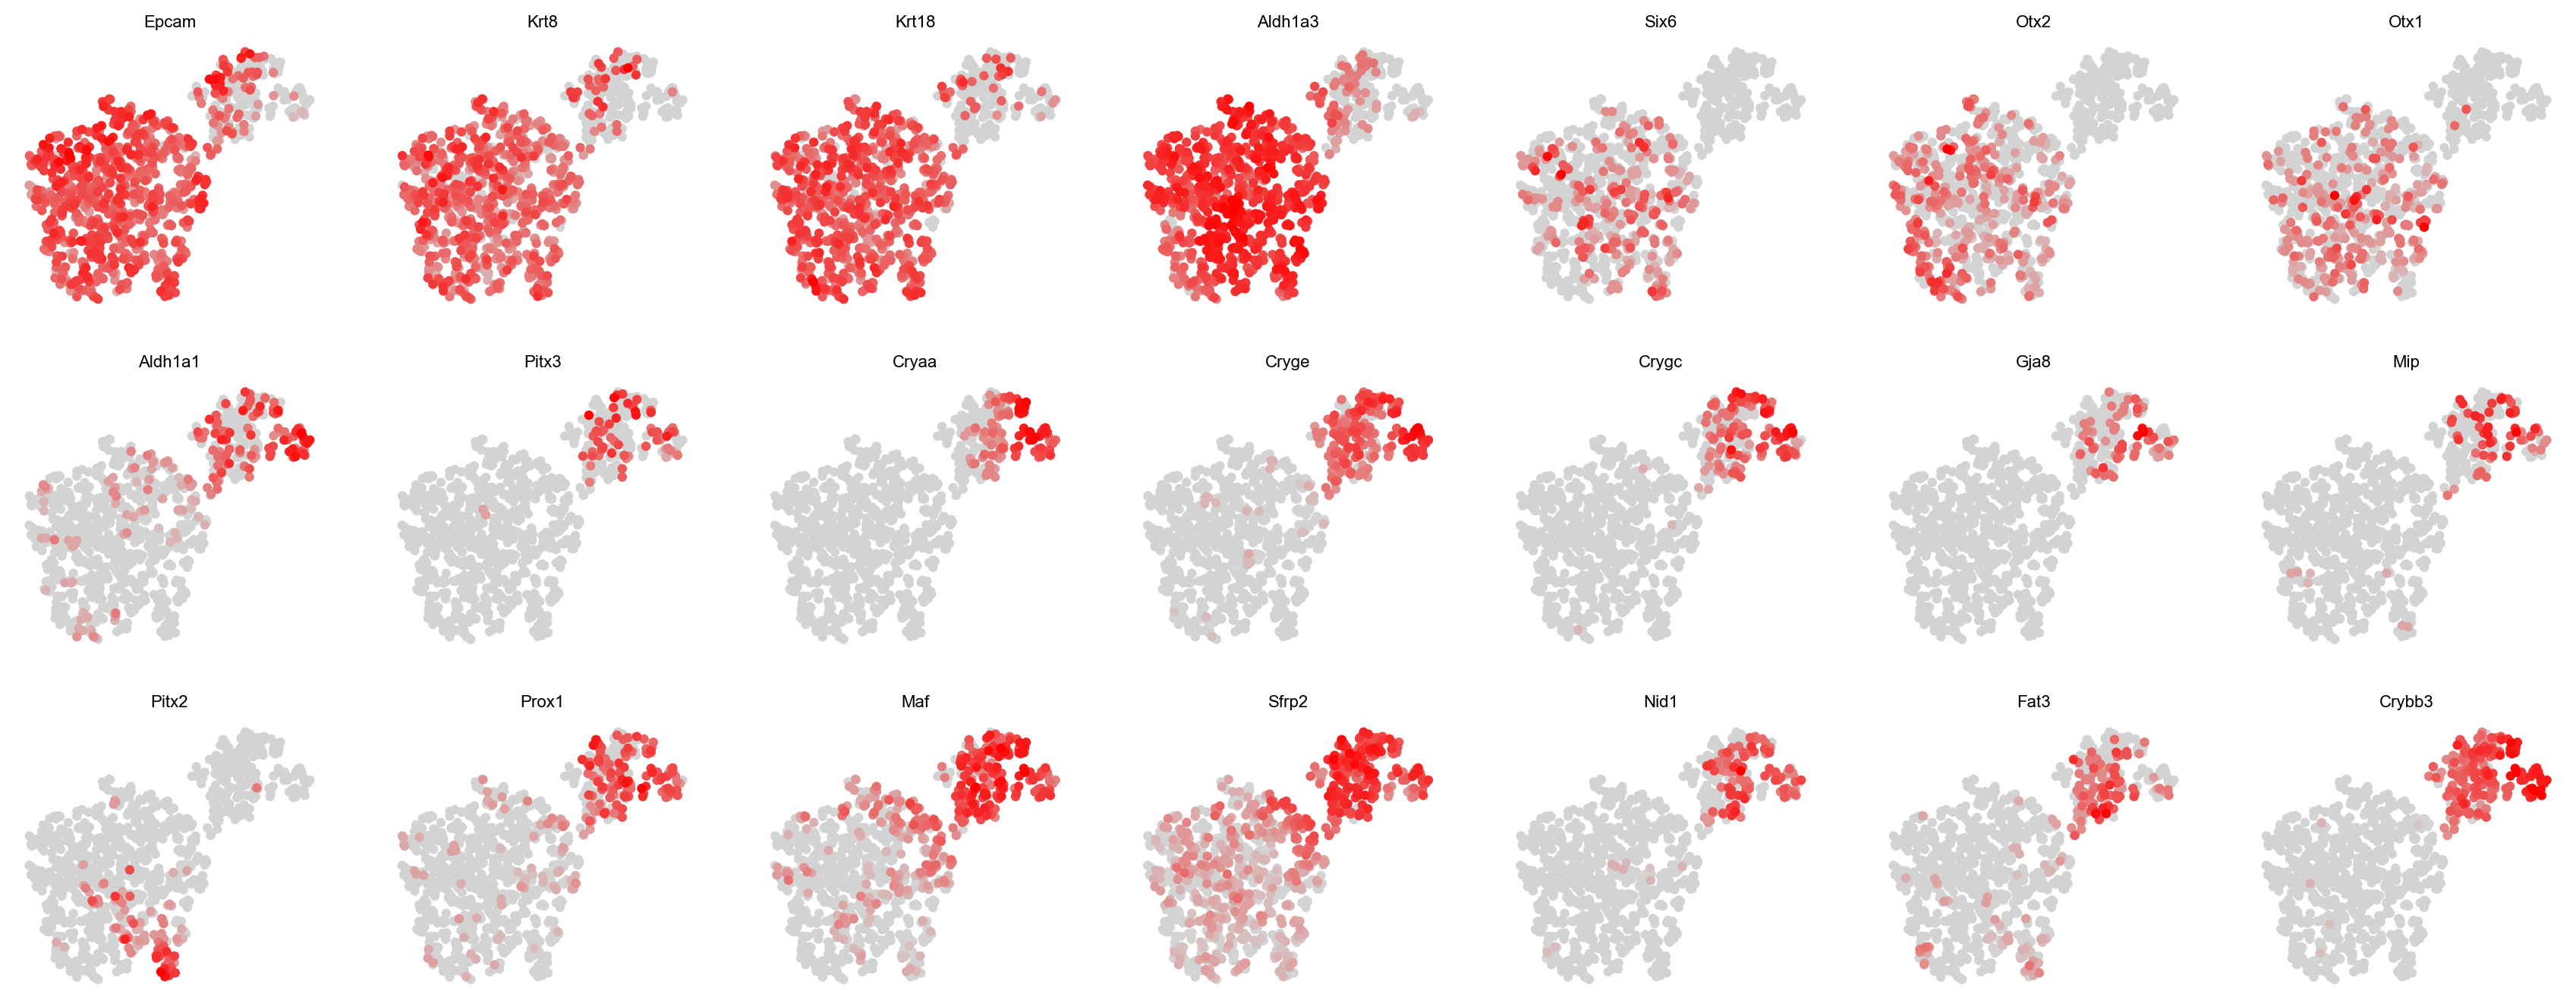

In [43]:
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
import math

# ============================================================
# 1. FIGURE SETTINGS — ADJUST HERE
# ============================================================

TITLE_SIZE = 8        # Gene names above each UMAP
COLORBAR_SIZE = 8     # Colorbar numbers
NCOLS = 7            # Number of UMAPs per row
POINT_SIZE = 80        # Size of individual cells
DPI = 300              # Resolution for rasterized UMAP points

PANEL_WIDTH = 3.0      # Width per UMAP (inches)
PANEL_HEIGHT = 2.5     # Height per UMAP (inches)

# Output directory
OUTDIR = Path.home()
FILENAME = "UMAP_markers_final"

# Custom colormap
grey_red = LinearSegmentedColormap.from_list(
    "grey_red",
    ["lightgrey", "red"]
)

# Arial font and editable text in Illustrator
mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": TITLE_SIZE,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "figure.dpi": 100,
    "savefig.dpi": DPI,
})

sc.set_figure_params(
    vector_friendly=True,
    dpi=100,
    dpi_save=DPI,
    fontsize=TITLE_SIZE
)

# ============================================================
# 2. MARKER GENES ORDERED BY CELL TYPE
# ============================================================

genes = [
    # Lens placode / early development
   
'Epcam', 'Krt8', 'Krt18', "Aldh1a3",'Six6','Otx2',  'Otx1',  'Aldh1a1',  
    "Aldh1a3",

    # Lens development / differentiation
    "Pitx3",
   
    "Aldh1a1",
   

    # Lens fiber differentiation
    "Cryaa",
  #  "Crybb3",
  #   "Cryab",
    "Cryge",
    "Crygc",
    "Gja8","Cryaa",  "Cryge", "Crygc",'Mip', 
    "Pitx2", 'Prox1',  'Maf', 'Sfrp2', 'Nid1', "Pitx3", "Mip",

    # Retina / ocular neural development
    "Fat3",  "Crybb3", "Cryge", "Crygc", "Cryaa"
]



# ============================================================
# 3. CHECK GENE AVAILABILITY
# ============================================================

# Remove duplicates, preserve order
genes = list(dict.fromkeys(genes))

# Include only genes available in AnnData
missing_genes = [
    g for g in genes
    if g not in adata.var_names
]

genes = [
    g for g in genes
    if g in adata.var_names
]

print(f"Number of genes to plot: {len(genes)}")

if missing_genes:
    print("\nMissing genes:")
    print(missing_genes)

if not genes:
    raise ValueError("No selected genes found in adata.var_names")

# ============================================================
# 4. GENERATE UMAP
# ============================================================

NROWS = math.ceil(len(genes) / NCOLS)

fig_width = NCOLS * PANEL_WIDTH
fig_height = NROWS * PANEL_HEIGHT

fig = sc.pl.umap(
    adata,
    color=genes,
    ncols=NCOLS,
    cmap=grey_red,
    size=POINT_SIZE,
    frameon=False,
    show=False,colorbar_loc=None,
    return_fig=True
)

# Set complete figure dimensions
fig.set_size_inches(fig_width, fig_height)

# ============================================================
# 5. RASTERIZE ONLY UMAP POINTS
# ============================================================

# Colorbars, gene names, and other text remain vectors
for ax in fig.axes:

    if ax.get_label() == "<colorbar>":
        continue

    for collection in ax.collections:
        collection.set_rasterized(True)

# ============================================================
# 6. ADJUST FONT SIZES
# ============================================================

for ax in fig.axes:

    # Gene titles
    if ax.get_title() in genes:
        ax.title.set_fontsize(TITLE_SIZE)
        ax.title.set_fontfamily("Arial")
        ax.title.set_fontweight("normal")

    # Colorbar labels
    else:
        ax.tick_params(
            axis="both",
            labelsize=COLORBAR_SIZE
        )

        for label in ax.get_yticklabels():
            label.set_fontfamily("Arial")

# ============================================================
# 7. SAVE PDF AND SVG
# ============================================================

#pdf_path = OUTDIR / f"{FILENAME}.pdf"
svg_path = OUTDIR / f"{FILENAME}.svg"



#fig.savefig(
#    svg_path,
#    format="svg",
#    dpi=DPI,
#    bbox_inches="tight",
 #   facecolor="white"
#)

#print("\nSaved files:")
print(pdf_path)
print(svg_path)

# ============================================================
# 8. DISPLAY
# ============================================================

plt.show()